# GOES Contrail Pipeline

This notebook takes two hours of GOES-19 Full Disk images from satellite imagery through to flight-matched contrails, in six steps:

1. Set up a `GOESDetector`.
2. Get the contrail detection masks.
3. Decompose the masks into individual contrails.
4. Track contrails between frames.
5. Get the flight data and advect it.
6. Match contrails to flights.

> Before running, set your API keys in `~/.env`, as described in the README.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Import contrail-detect modules (more below)
from contrail_detect.core.common import Colors
from contrail_detect.core.config import DATA_DIR, FIGURE_DIR
from contrail_detect.geostationary.abc import Geostationary
from contrail_detect.models.contrail_model_base import ContrailModelBase

colors = Colors()

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(name)s - %(levelname)s - %(message)s",
)

In [2]:
# Display valid datetime ranges for satellite & detection options
Geostationary.display_valid_datetime_ranges()
ContrailModelBase.display_detection_dates()


Valid datetime ranges for geostationary satellites:

Satellite       | Start Date           | End Date            
-------------------------------------------------------------
GOES-16         | 2019-04-02 16:00     | 2025-04-07 00:00    
GOES-18         | 2023-01-04 18:00     | present             
GOES-19         | 2025-04-07 00:00     | present             
HIMAWARI-8      | 2015-07-07 02:00     | 2022-12-13 04:50    
HIMAWARI-9      | 2022-11-04 15:50     | present             
MTG             | 2025-08-26 07:00     | present             
-------------------------------------------------------------


Valid datetime ranges for contrail detection sources:

Name                 | Type            | Satellites                | Start              | End                | Notes                                        
------------------------------------------------------------------------------------------------------------------------------------------------------------
Contrails API    

## Detector Set-up

Here, we set up a `GOESDetector` object for 2 hours of GOES-19 Full Disk images.

In [3]:
from contrail_detect.geostationary.goes import GOESDetector

In [4]:
satellite = "GOES-19"
region = "F"
start_time = np.datetime64("2026-01-09T15:00:00")
end_time = np.datetime64("2026-01-09T17:00:00")

goes_detector = GOESDetector(
    goes_satellite=satellite,
    goes_region=region,
    extent=None,
    start_time=start_time,
    end_time=end_time,
)

#### Ash RGB Image

The [Ash RGB](https://www.rammb.cira.colostate.edu/training/visit/quick_guides/GOES_Ash_RGB.pdf) false colour image is built from ABI bands 11, 14, and 15, and is the usual way to view contrails, as thin, high ice clouds (e.g., contrails and cirrus) appear dark blue. This plot is optional.

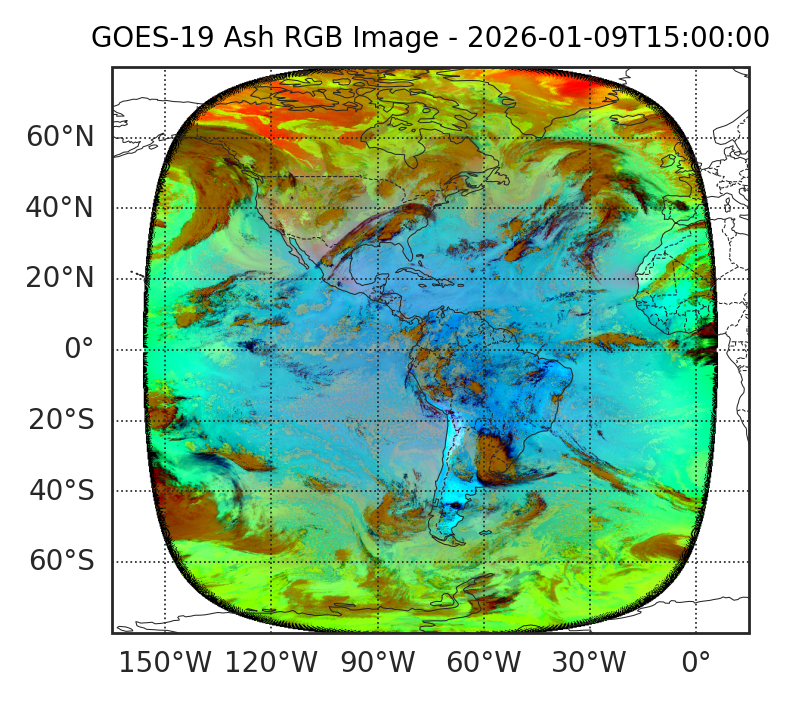

In [5]:
plot_ash_rgb = True

if plot_ash_rgb:
    goes_rgb, goes_crs, goes_extent = goes_detector.fetch_image(goes_detector.timestamp_sequence[0])

    if goes_rgb is not None:
        fig = goes_detector.plot_ash_rgb(
            ash_rgb=goes_rgb,
            img_extent=goes_extent,
            img_transform=goes_crs,
            title_text=f"{satellite} Ash RGB Image - {start_time}",
        )
        plt.show()

#### Tiling

This optional plot shows the tiles used for local inference. Each tile is 256×256 pixels and is reprojected from the geostationary view. Tiles are close to square near the sub-satellite point (75°W, 0°) and become more distorted towards the edge of the disk.

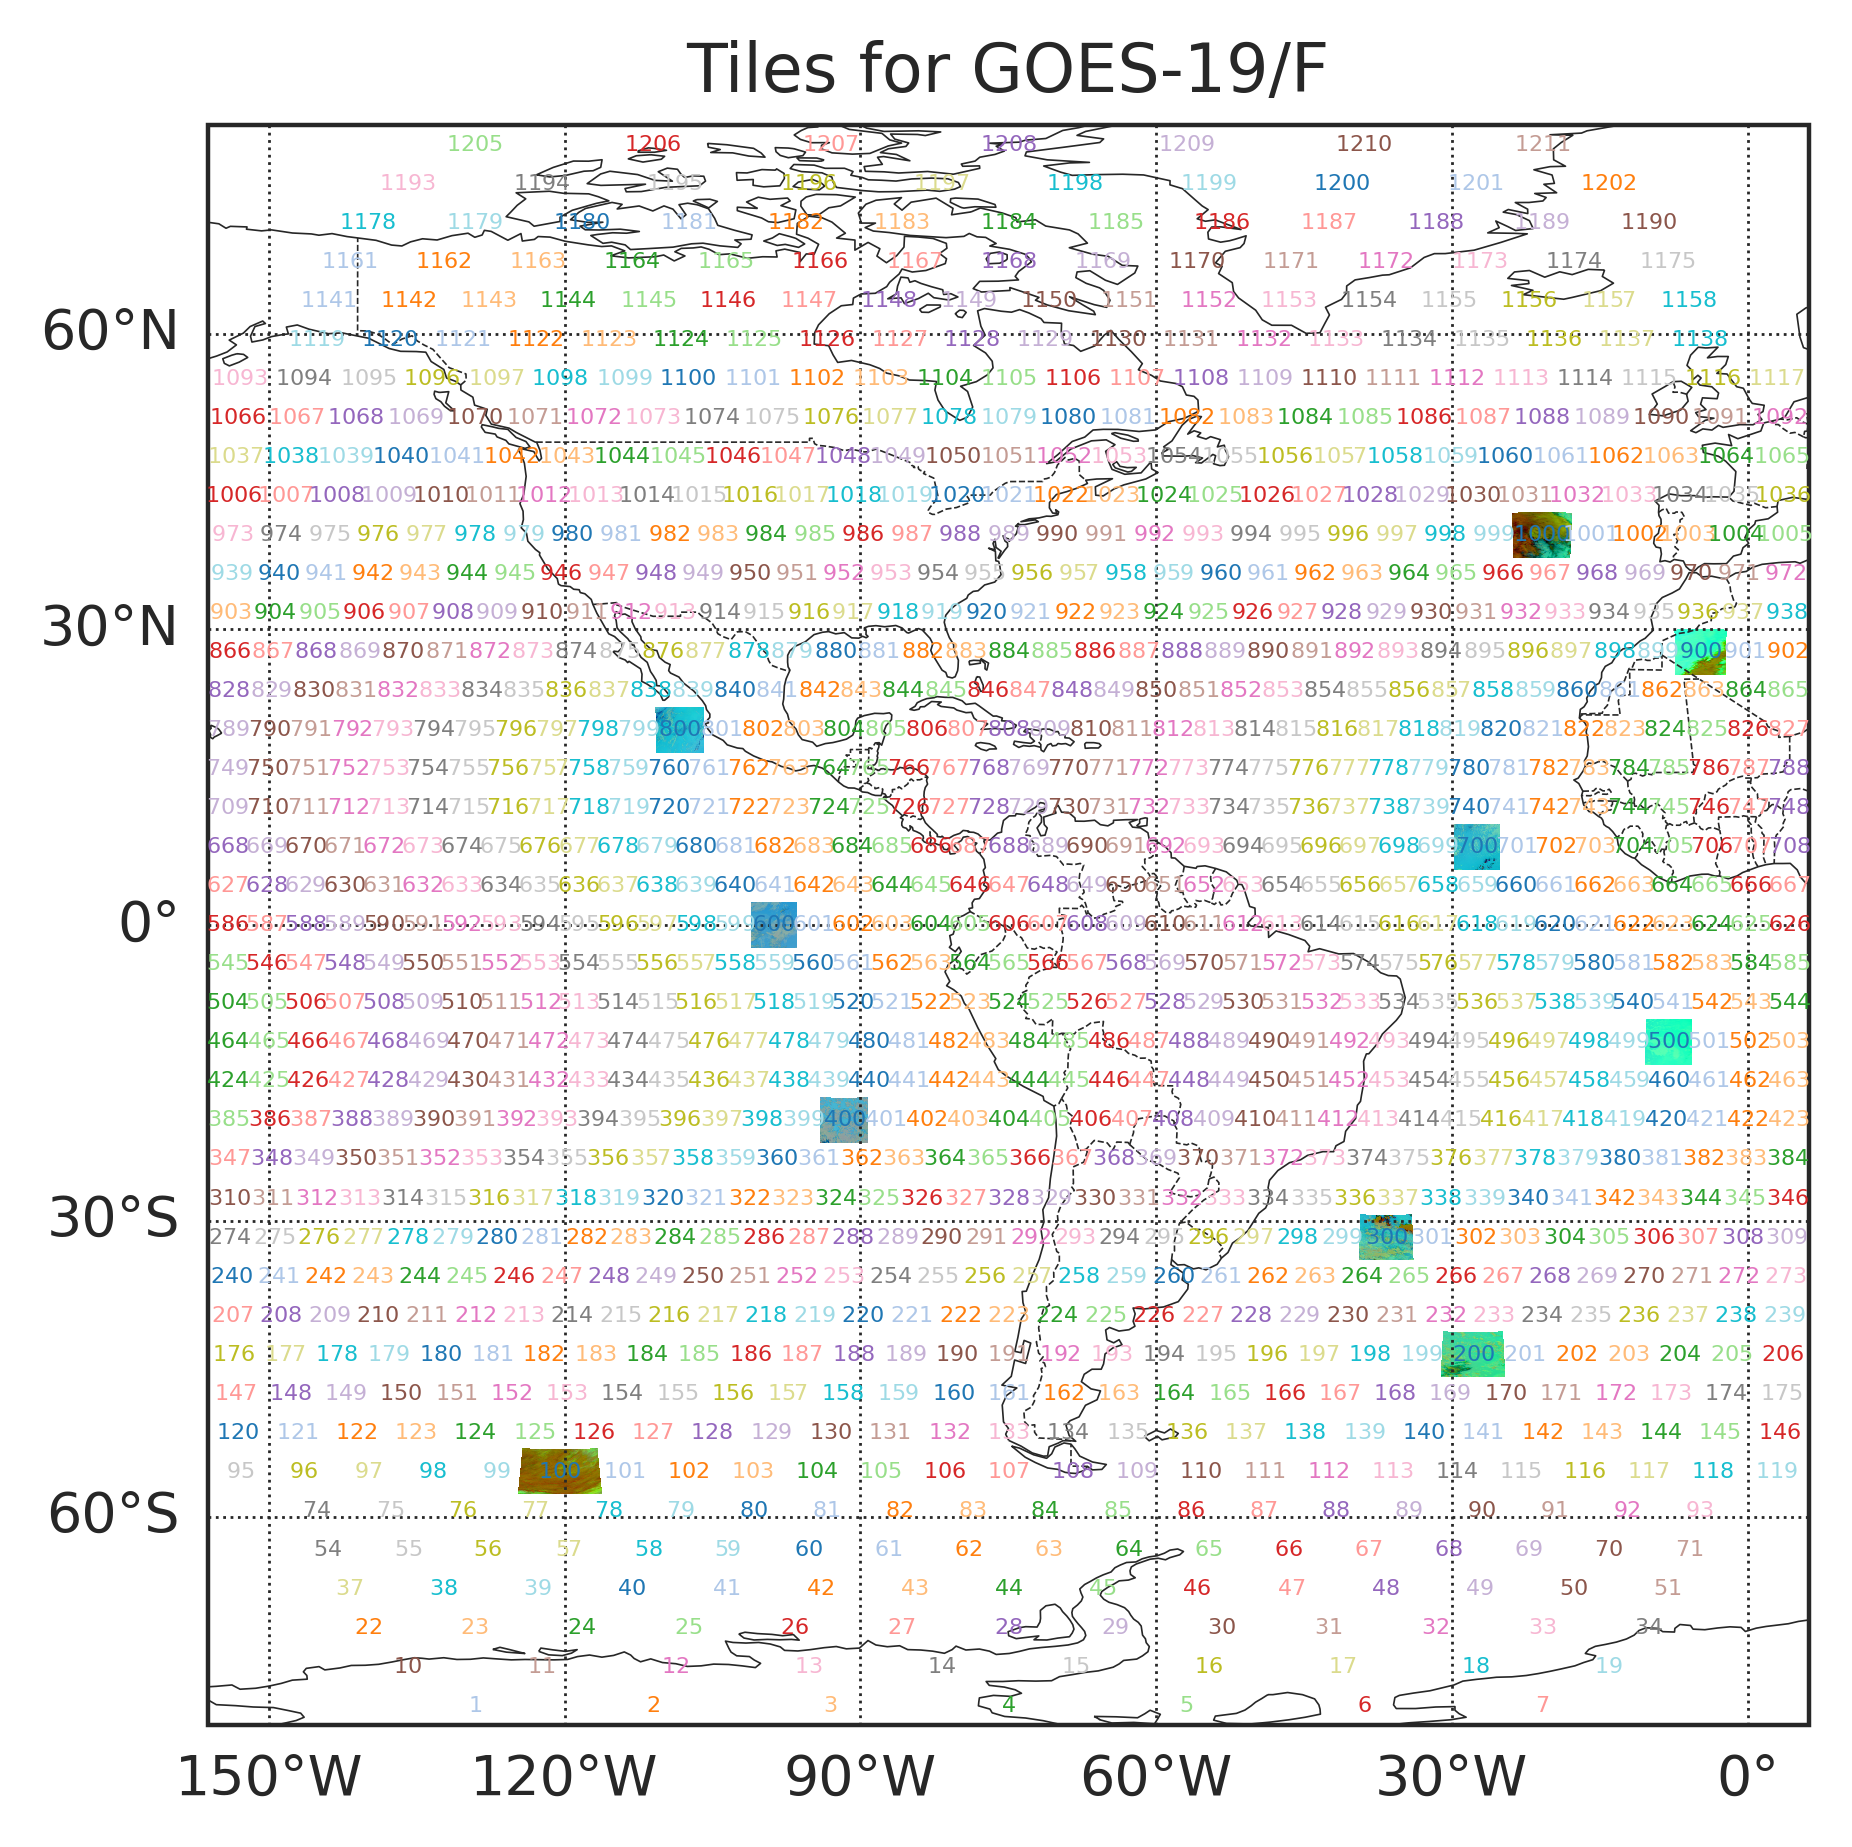

In [6]:
plot_goes_tiling = True

if plot_goes_tiling:
    fig = goes_detector.plot_abi_test_tiles(
        tiles=np.arange(100, 1100, 100, dtype=int),
        global_view=False,
        numbered=True,
    )
    plt.show()

## Contrail Detection

We get the detection masks using one of three methods:

- `local` runs the detection model locally. This requires the `[local]` extra, the model weights, and a GPU, selected with `device_indices` (or `"CPU"`, which is much slower).
- `contrails_api` retrieves them from the Contrails.org API and requires a Contrails.org API key.
- `google_api` retrieves them from the Google Contrails API and requires a Google Contrails API key.

Detections are cached locally. To retrieve them again, set `force_reprocess_detections = True`.

In [7]:
detection_method = "contrails_api"  # or "local", "google_api"

device_indices = [0]  # GPU indices, or "CPU"; for "local" only

force_reprocess_detections = False

In [8]:
detections = goes_detector.get_detections(
    method=detection_method,
    device_ids=device_indices,
    force_reprocess=force_reprocess_detections,
)

In [9]:
goes_detector.detections = detections

#### Detection Masks

This optional plot shows the detection masks beside the Ash RGB image for each chosen timestamp. To save the figures rather than show them, pass `fig_output_dir` to `plot_detections`.

Plotting Full Disk detections:   0%|          | 0/1 [00:00<?, ?it/s]

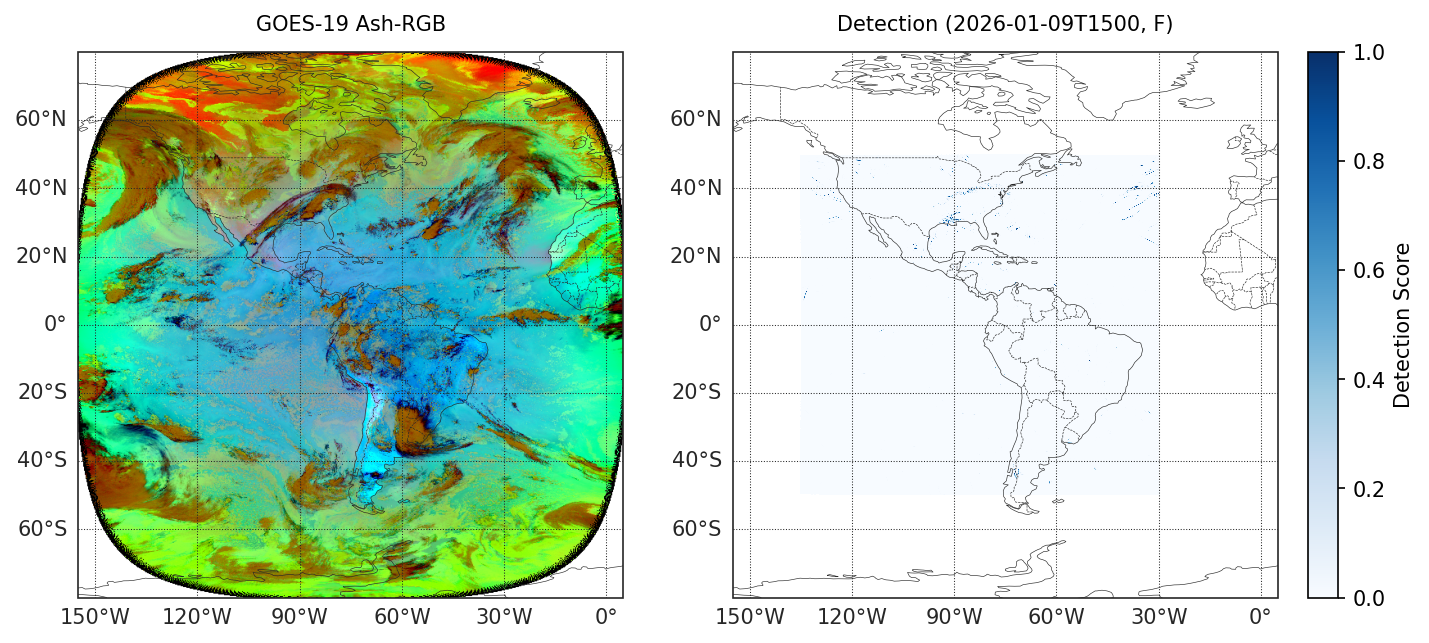

In [10]:
plot_goes_detections = True

timestamps_to_plot = goes_detector.timestamp_sequence[:1]

if plot_goes_detections:
    figures = goes_detector.plot_detections(timestamps=timestamps_to_plot, bbox=None)
    plt.show()

## Detection Mask Decomposition

Next, we split the detection masks into individual contrails using one of two methods:

- `decomposer` decomposes the masks locally.
- `google_api` retrieves line segments from the Google Contrails API, without point clouds, and requires a Google Contrails API key. The match plot at the end of this notebook needs point clouds and is thus skipped with this method.

The decomposer takes two settings. First, `prediction_threshold` is the detection threshold, i.e., the detection score below which pixels are dropped. If it is left as `None`, the default for the detection source is used (0.30 for the local model and Contrails.org detections, and 0.40 for Google's). Second, `contrail_stitching` sets whether fragments split from overlapping contrails are joined back into whole contrails.

The decomposer writes `contrail_summary`, with one row per contrail, and `contrail_points`, with the lat-lon point cloud of each contrail. Each contrail is identified by a `contrail_id` of the form `{satellite}-{region}-{YYYYMMDD-HHMM}-{lat}-{lon}-{hash}`, where the final six characters are a hash of the contrail's pixels, so the same data always give the same IDs.

As with detections, the results are cached. To decompose the masks again, set `force_reprocess_decomposition = True`.

In [11]:
decomposition_method = "decomposer"  # or "google_api"

prediction_threshold = None  # default for the detection source

contrail_stitching = True  # "decomposer" only

force_reprocess_decomposition = False

In [12]:
line_segs, point_clouds = goes_detector.get_decomposed_contrails(
    method=decomposition_method,
    prediction_threshold=prediction_threshold,
    contrail_stitching=contrail_stitching,
    force_reprocess=force_reprocess_decomposition,
)

In [13]:
goes_detector.contrail_summary = line_segs
goes_detector.contrail_point_clouds = point_clouds

#### Decomposed Contrails

This optional plot shows the detection mask beside the contrails decomposed from it, over a busy region of the US Gulf Coast. Each contrail is drawn with its own colour and centre line, so crossing contrails that form a single connected region in the mask appear as separate contrails. The contrails are shown unstitched, as in dense crossings a stitched contrail can take in much of its region.

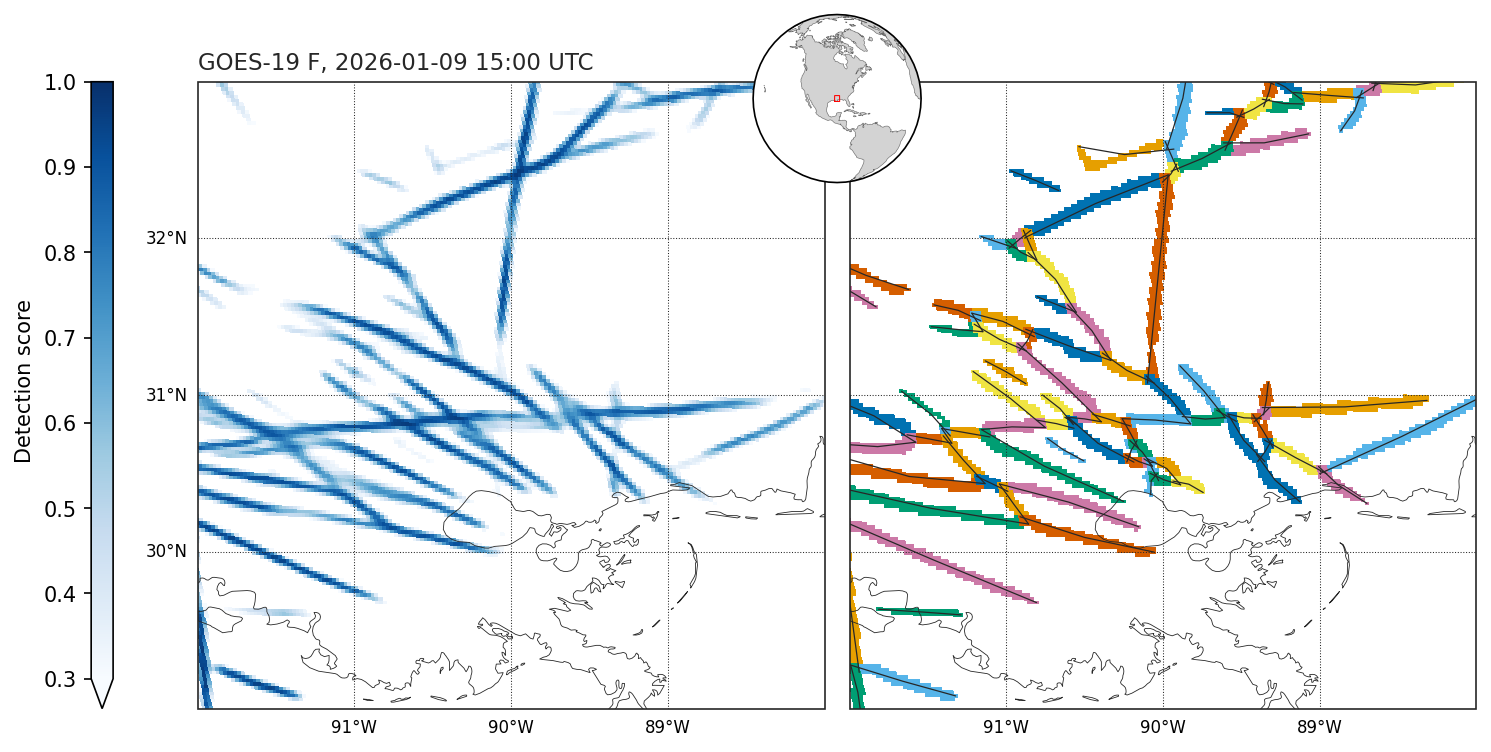

In [14]:
plot_decomposition = True

if plot_decomposition:
    # Unstitched decomposed contrails, for display only; the pipeline above keeps contrail_stitching
    unstitched_segs, unstitched_points = goes_detector.get_decomposed_contrails(
        method="decomposer",
        prediction_threshold=prediction_threshold,
        contrail_stitching=False,
    )
    fig = goes_detector.plot_decomposition(
        timestamp=goes_detector.timestamp_sequence[0],
        bbox=(-92.0, -88.0, 29.0, 33.0),
        contrail_summary=unstitched_segs,
        point_clouds=unstitched_points,
    )
    plt.show()

## Contrail Tracking

Here, we link contrails across frames into tracks. A Kalman filter predicts the position of each contrail, and the Hungarian algorithm assigns detections to tracks frame by frame.

> Tracks do not continue across gaps in the image sequence (e.g., data outages or day/night transitions). Thus, a contrail seen on both sides of a gap is given two tracks.

In [15]:
from contrail_detect.tracking import generate_tracking_GIF, plot_tracks
from contrail_detect.tracking.tracking import TrackingConfig

### Tracking Configuration

By default, the package allows one skipped frame, applies a 0.8° vicinity gate and a 10 km perpendicular gate, and initialises new tracks with ERA5 wind velocities. Any field can be overridden to tune the tracking, e.g., `TrackingConfig(max_frames_to_skip=0)`, or `TrackingConfig(use_wind_initialization=False)` to initialise tracks without ERA5 winds.

In [16]:
tracking_config = TrackingConfig()

### Run & Examine Tracking

Tracking adds a `track_id` to `contrail_summary`, and `summarize_tracks` reports how many contrails were tracked and the length of the tracks. Contrails that are not linked to any other contrail are not given a `track_id`. Wind initialisation downloads ERA5 data and thus requires a valid `.cdsapirc`, either in your home directory or at `path_to_key`.

In [17]:
goes_detector.get_tracking_output(
    force_reprocess=True,
    tracking_config=tracking_config,
    estimated_contrail_height_ft=3.5e4,
    path_to_key=None,
)

82492cbd25da62868d01d6a24fc88539.nc:   0%|          | 0.00/2.21G [00:00<?, ?B/s]

In [18]:
goes_detector.summarize_tracks()

Contrail Tracking Summary
Total contrail detections : 4604
Total tracks              : 922
  Single-frame tracks     : 0 (0.0%)
  Multi-frame tracks      : 922 (100.0%)
Detections in multi-frame : 3986 / 4604 (86.6%)

Frames per track:
  min      : 2
  median   : 4.0
  mean     : 4.32
  max      : 13
  possible : 13 (total no. frames)

Track time span (minutes):
  min      : 10.0
  median   : 30.0
  mean     : 34.66
  max      : 120.0
  possible : 120.0 (total time span)

Mean contrail length per track (km):
  min      : 12.5
  median   : 62.2
  mean     : 82.72
  max      : 807.9


#### Tracks

These optional plots show a map of contrail centroids along each track and a GIF of the tracks in a zoomed region (off by default).

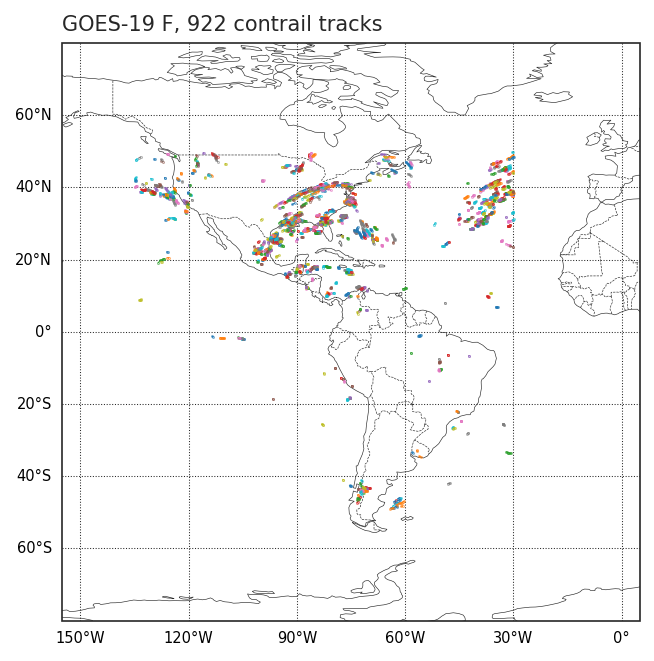

In [19]:
plot_track_properties = True

if plot_track_properties:
    fig = plot_tracks(goes_detector)
    plt.show()

In [20]:
plot_tracking_gif = False

if plot_tracking_gif:
    generate_tracking_GIF(
        detector=goes_detector,
        zoom_extent=[-102.5, -97.5, 20.0, 25.0],
        n_ghost_frames=4,
        save_path=(FIGURE_DIR / "tracking_animation" / "tracking_example.gif"),
    )

## Flight Data and Advection


Here, we retrieve flight data (in this case, ADS-B from the Contrails.org API) and advect it with ERA5 winds to the scan time of each pixel.

### Retrieval of Flight Data

`adv_max` sets how far back from each frame flights are advected, which also caps the implied age of a match, and `adv_timestep` is the advection step in minutes.

We then choose a flight data source:

- `contrails_api` retrieves ADS-B data from the Contrails.org API and requires a Contrails.org API key.
- `local` loads your own flight data from a file (e.g., CSV or Parquet) using `GenericFlightData`.

In [21]:
from contrail_detect.flights import plot_flight_coverage
from contrail_detect.flights.contrails_api import ContrailsAPIFlightData
from contrail_detect.flights.generic import GenericFlightData

In [22]:
adv_max = np.timedelta64(60, "m")

adv_timestep = 10  # minutes

In [23]:
flight_data_source = "contrails_api"  # or "local"

if flight_data_source == "local":
    path_to_flight_data = DATA_DIR / "flight_data" / "<FILENAME>.parquet"
    flights = GenericFlightData()
    flights.load_from_dataframe(pd.read_parquet(path_to_flight_data))

if flight_data_source == "contrails_api":
    flights = ContrailsAPIFlightData(
        req_timestamps=goes_detector.timestamp_sequence,
        adv_max=adv_max,
        req_bbox=None,
        add_bbox_buffer=None,
    )
    flights.download_from_api()

#### ADS-B Coverage

This optional plot shows the waypoint density across the downloaded flights, on a log scale.

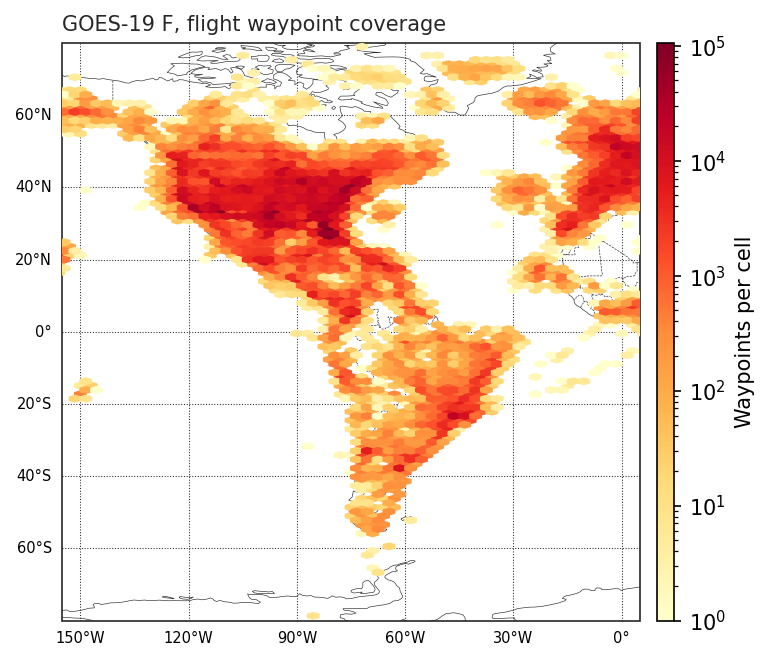

In [24]:
plot_adsb_coverage = True

if plot_adsb_coverage:
    fig = plot_flight_coverage(goes_detector, flights.flight_data)
    plt.show()

### Retrieval of Meteorological Data

We retrieve ERA5 winds from the Climate Data Store through pycontrails. Advection requires only the wind components, which keeps downloads small. However, the Climate Data Store serves whole days, so this may download more data than the flights require.

Downloading requires a valid `.cdsapirc`, either in your home directory or at `path_to_key`.

In [25]:
from contrail_detect.meteorology.ecmwf import get_era5_from_local

In [26]:
# Winds from the first frame minus the lookback to the end of the last frame
frames = goes_detector.timestamp_sequence
met_dataset = get_era5_from_local(
    times=[frames[0] - adv_max, frames[-1] + (frames[1] - frames[0])],
    met_variables=["eastward_wind", "northward_wind"],
    file_path_met=None,
    path_to_key=None,
)

In [27]:
# Rename variables to match expected names in advection function
met_dataset = met_dataset.rename(
    {
        "eastward_wind": "u",
        "northward_wind": "v",
    }
)

flights.ecmwf_data = met_dataset

### Advection of Flight Data to Contrail Detections

For each flight waypoint, advection first finds the satellite pixel containing the flight. Next, it determines when the scan reaches that pixel (see [ABI scan modes](https://www.goes-r.gov/users/abiScanModeInfo.html)). Finally, it moves the flight with the ERA5 winds at its location and altitude to that scan time.

In [28]:
flights.advect_flights_to_scan_times(
    detector=goes_detector,
    adv_max_past=adv_max,
    adv_timestep=adv_timestep,
    save_output=True,
)

## Contrail-Flight Attribution

Here, we match each contrail track to the flight that most likely formed it. First, candidate flights are identified as those with advected waypoints near the contrail. Each candidate is scored with a distance metric, by default the RMS perpendicular distance (km) between the contrail and the advected flight path, where lower is better. Flight positions are adjusted for parallax beforehand, because the satellite sees high-altitude objects displaced from their true position.

The top-ranked candidates for each track are written to `matching_results`. A match preset (`strict`, `default`, or `relaxed`) then accepts the rank-1 flight of a track when its score is low enough, when it is clearly better than rank 2, and when the mean age of its waypoints along the contrail at first detection lies between 6.5 min and a limit set by the preset (17.5 min, 29.7 min, and 48.5 min for `strict`, `default`, and `relaxed`, respectively).

In [29]:
from contrail_detect.matching import Matcher, MatchingConfig, match_tracks
from contrail_detect.matching.matching_viz import plot_match

In [30]:
matcher = Matcher(detector=goes_detector, flights=flights)

### Matching Configuration

By default, the package scores candidates by RMS perpendicular distance, combines the first three frames of each track with a weighted mean, and considers flights within 0.5° of the contrail with at least 5 points. Only tracks of at least 3 frames are matched (`min_track_frames`), while shorter tracks and untracked contrails are still scored frame by frame but left unmatched. Any field can be overridden to tune the matching, e.g., `MatchingConfig(min_points=3)` for sparser flight data.

In [31]:
matching_config = MatchingConfig()

### Run Matching

In [32]:
matcher.run_matching(config=matching_config)
matching_results = matcher.matching_results.copy()

# Tracks long enough to be matched and with at least one ranked candidate flight
ranked = matching_results["t_status"] == "ranked"
n_ranked = matching_results.loc[ranked, "track_id"].nunique()
print(
    f"Matching complete: {len(matching_results)} contrail rows, "
    f"{n_ranked} tracks with ranked candidate flights"
)

Matching complete: 4604 contrail rows, 456 tracks with ranked candidate flights


In [33]:
matched_tracks = match_tracks(matching_results, preset="default")  # or "strict", "relaxed"

print(f"{len(matched_tracks)} of {n_ranked} ranked tracks matched")

118 of 456 ranked tracks matched


In [34]:
# Save the results and scores to matching_data, in the data directory
save_matching_results = True

if save_matching_results:
    ts_start = pd.to_datetime(start_time).strftime("%Y%m%dT%H%M")
    ts_end = pd.to_datetime(end_time).strftime("%Y%m%dT%H%M")
    stem = f"{satellite}_{region}_{detection_method}_{decomposition_method}_{ts_start}_{ts_end}"
    matching_data_dir = DATA_DIR / "matching_data"
    matching_data_dir.mkdir(parents=True, exist_ok=True)

    matching_results.to_parquet(matching_data_dir / f"{stem}.parquet", index=False)
    print(f"Matching results saved to {matching_data_dir.name}/{stem}.parquet")

    matcher.save_scores(matching_data_dir / f"{stem}_scores.parquet")
    print(f"Scores saved to {matching_data_dir.name}/{stem}_scores.parquet")

Matching results saved to matching_data/GOES-19_F_contrails_api_decomposer_20260109T1500_20260109T1700.parquet
Scores saved to matching_data/GOES-19_F_contrails_api_decomposer_20260109T1500_20260109T1700_scores.parquet


### Inspect Scores & Matches

`matcher.scores` holds the raw score for each contrail and candidate flight. `matching_results` has one row per contrail, with the top three candidates and their scores in the `t1`, `t2`, and `t3` columns.

In addition to the `contrail_summary` columns, each candidate has its RMS distance (km, lower is better), the implied contrail age and altitude from the matched waypoints, the earliest and latest waypoint times within the contrail, the oldest and mean age of the waypoints along the contrail (`first_formation_point_age_seconds` and `mean_formation_point_age_seconds`, respectively; the presets cut on the mean), and the number of advected waypoints both in the search box and within the contrail.

In [35]:
df_scores = matcher.scores
print(f"Score rows: {len(df_scores)}")

df_scores.iloc[0]

Score rows: 156867


contrail_id                          GOES-19-F-20260109-1500-N10.1-W76.6-2fcf7e
timestamp                                                   2026-01-09 15:00:00
flight_id                                  8570cff4-ca60-47cd-8f57-42f8c040b8e8
rms_distance                                                           0.309691
mean_implied_age_seconds                                            1075.857143
min_implied_age_seconds                                                   998.0
max_implied_age_seconds                                                  1147.0
implied_altitude_ft                                                     39250.0
first_formation_point_time                                  2026-01-09 14:46:10
last_formation_point_time                                   2026-01-09 14:47:00
first_formation_point_age_seconds                                        1048.0
mean_formation_point_age_seconds                                         1024.0
num_points                              

In [36]:
for col in matching_results.columns:
    print(f"{col}: {matching_results.iloc[0][col]}")

timestamp: 2026-01-09 15:00:00
solidity: 0.8333333333333334
eccentricity: 0.9940206442716601
originally_complex: False
is_processed: nan
contrail_id: GOES-19-F-20260109-1500-N10.1-W76.6-2fcf7e
n_pixels: 80
centroid_lat: 10.1337
centroid_lon: -76.5867
centroid_scantime: 2026-01-09 15:03:38.528000
endpoint1_lat: 10.2629
endpoint1_lon: -76.3676
endpoint1_scantime: 2026-01-09 15:03:38.556000
endpoint2_lat: 10.0032
endpoint2_lon: -76.8066
endpoint2_scantime: 2026-01-09 15:03:38.501000
orientation: -120.8
great_circle_length_km: 56.04
area_km2: 332.07
width_km: 5.93
mean_score: 0.6314976148307323
min_score: 0.30783963203430176
max_score: 0.8902958631515503


std_score: 0.18407369545089752
u_init: 17.03546142578125
v_init: 8.162338256835938
track_id: GOES-19-F-20260109-1500-N10.1-W76.6-2fcf7e
tracked: True
first_in_track: True
track_length: 9
scored_in_track: True
t_status: ranked
t1_match: 8570cff4-ca60-47cd-8f57-42f8c040b8e8
t1_rms_distance: 0.9861970839038053
t1_mean_implied_age_seconds: 1076.0
t1_min_implied_age_seconds: 998.0
t1_max_implied_age_seconds: 1147.0
t1_implied_altitude_ft: 39250.0
t1_first_formation_point_time: 2026-01-09 14:46:10
t1_last_formation_point_time: 2026-01-09 14:47:00
t1_first_formation_point_age_seconds: 1048.0
t1_mean_formation_point_age_seconds: 1024.0
t1_num_points: 13.0
t1_num_within_span: 7.0
t1_n_candidates_scored: 7.0
t1_scoring_area_km2: 22064.4
t1_implied_formation_timestamp: 2026-01-09 14:42:04
t2_match: a4990f8c-736d-4b1c-bb69-77af9b942db5
t2_rms_distance: 14.452853179149407
t2_mean_implied_age_seconds: 1189.0
t2_min_implied_age_seconds: 998.0
t2_max_implied_age_seconds: 1294.0
t2_implied_altitude_ft:

#### Implied Age

This optional plot shows the mean age of the waypoints of the rank-1 flight along the contrail, i.e., the time between the flight passing and the contrail being observed. It is shown both for every contrail in the tracks that the preset accepted and for the first detection in each of those tracks (i.e., the age on which the presets cut).

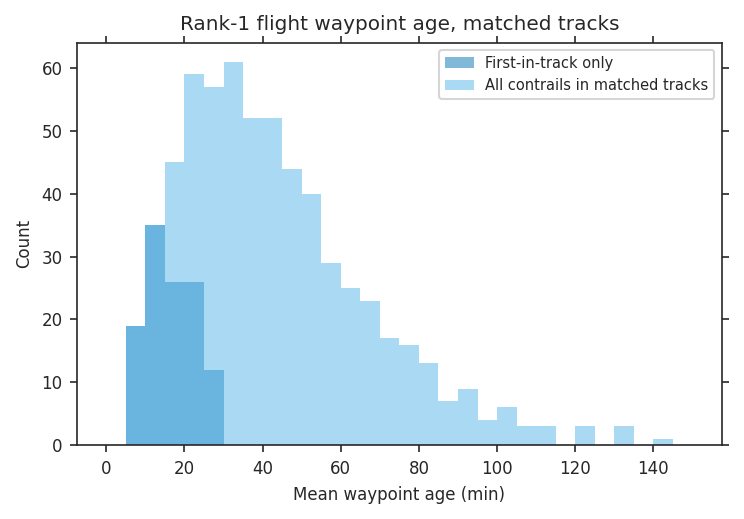

In [37]:
plot_time_distribution = True

if plot_time_distribution:
    # Contrails in tracks the preset accepted
    accepted = matching_results[matching_results["track_id"].isin(matched_tracks.index)]
    age_col = "t1_mean_formation_point_age_seconds"
    ages_all = accepted[age_col].dropna() / 60

    # First detection in each accepted track
    ages_first = accepted.loc[accepted["first_in_track"], age_col].dropna() / 60

    fig = plt.figure(figsize=(5, 3.5), dpi=150)
    plt.rcParams.update({"font.size": 8})
    with sns.axes_style(colors.plot_params_light):
        ax = fig.add_subplot(111)
        ax.hist(
            ages_first,
            bins=np.arange(0, 155, 5),
            color=colors.wong[-3],
            edgecolor="none",
            alpha=0.5,
            label="First-in-track only",
        )
        ax.hist(
            ages_all,
            bins=np.arange(0, 155, 5),
            color=colors.wong[2],
            edgecolor="none",
            alpha=0.5,
            label="All contrails in matched tracks",
        )

        ax.set_xlabel("Mean waypoint age (min)")
        ax.set_ylabel("Count")
        ax.set_title("Rank-1 flight waypoint age, matched tracks")
        ax.legend(fontsize=7)

        fig.tight_layout()
        plt.show()

### Visualise a Single Match

Here, we plot the matched track with the lowest rank-1 score, with one panel per frame of its track. Each panel shows the contrail, the original path of the flight, and the flight advected to the scan times of that frame. For an interactive version with a time slider, use `display_match` from the same module.

In [38]:
# Among the tracks the preset accepted, pick the one with the lowest rank-1 score
track_id = matched_tracks["t1"].idxmin()
flight_id = matching_results.loc[matching_results["track_id"] == track_id, "t1_match"].iloc[0]

matcher.summarize_match(track_id)

  ─────────────────────────────────────────────────────────────────────────
  Track ID                           GOES-19-F-20260109-1610-N36.2-W92.7-6928e2
  Contrail ID                        GOES-19-F-20260109-1610-N36.2-W92.7-6928e2
  Timestamp                          2026-01-09 16:10:00
  ─────────────────────────────────  ──────────────────────────────────────
  Rank-1 flight                      2fe142c8-770e-4034-aedd-6fc1288bf6ce
  RMS distance (km)                  0.7213
  first_formation_point_age_seconds  485
  mean_formation_point_age_seconds   422.2
  n_candidates_scored                43
  scoring_area_km2                   1.44e+04
  Mean implied age                   6.8 min
  Implied altitude                   37670 ft
  Formation timestamp                2026-01-09 16:03:13
  First formation pt                 2026-01-09 16:03:32
  Last formation pt                  2026-01-09 16:05:31
  Points within span                 11 / 19
  ──────────────────────────────────

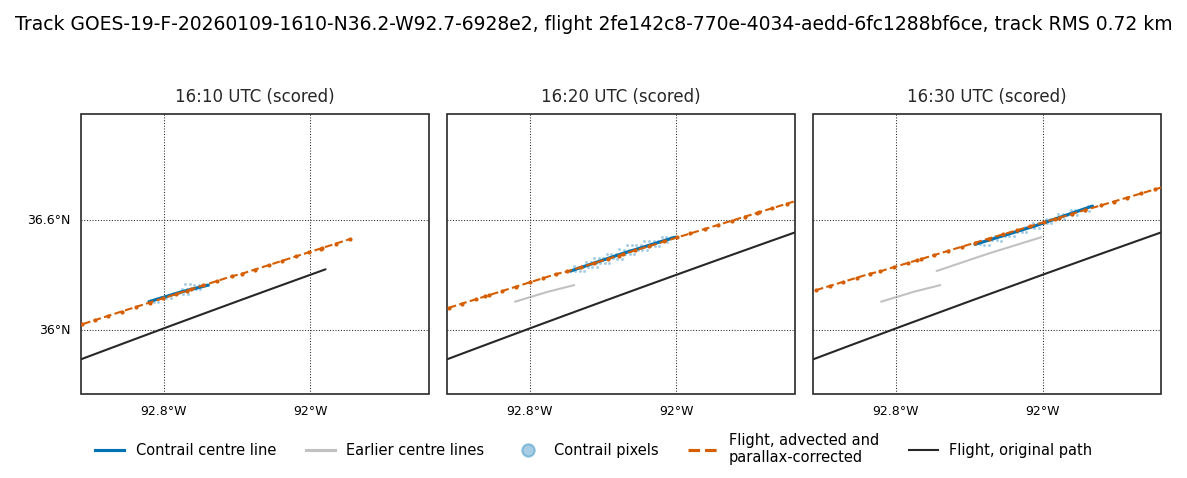

In [39]:
# The plot draws the contrails' pixels, which only the decomposer provides
if decomposition_method == "decomposer":
    # Geo point clouds (contrail pixels in lon/lat) for drawing the track's contrails
    geo_point_clouds = goes_detector.get_geo_point_clouds(
        method=decomposition_method,
        prediction_threshold=prediction_threshold,
        contrail_stitching=contrail_stitching,
    )

    fig = plot_match(
        track_id=track_id,
        flight_id=flight_id,
        matching_results=matching_results,
        adv_flight_data=flights.adv_flight_data,
        geo_point_clouds=geo_point_clouds,
        flight_data=flights.flight_data,
    )
    plt.show()